# Analise de dados - Diagnostic da Saúde Financeira e Eficiência Operacional
## 1. Definição do problema do negócio.
A diretoria não possui uma visão integrada que conecte o volume de vendas, os custos operacionais (COGS) e a concessão de descontos com a lucratividade real por região e segmento. A principal dúvida estratégica é: quais segmentos e mercados estão realmente gerando valor financeiro líquido e onde estamos perdendo margem por excesso de descontos ou custos operacionais elevados?
## 1.1. Dataset
https://www.kaggle.com/datasets/atharvaarya25/financials/data
## 1.2. Informações gerais
O dataset possui diversas variáveis, quais sejam:
- Segment: Segmento de mercado ao qual o cliente pertence (ex.: Government, Midmarket, Enterprise, Small Business, Channel Partners).
- Country: País onde a venda foi realizada.
- Product: Nome do produto comercializado (ex.: Carretera, Montana, Paseo).
- Discount Band: Faixa ou nível de desconto aplicado à transação (ex.: None, Low, Medium, High).
- Manufacturing Price: Custo unitário de fabricação do produto.
- Sale Price: Preço unitário de venda cobrado pelo produto.
- Gross Sales: Receita bruto total da venda, calculado pela multiplicação de Units Sold por Sale Price ($\text{Units Sold} \times \text{Sale Price}$).
- Discounts: Valor total do desconto concedido na transação.
- Sales: Receita líquido da venda, correspondente ao valor bruto deduzido dos descontos ($\text{Gross Sales} - \text{Discounts}$).
- COGS: Sigla para Cost of Goods Sold (Custo dos Produtos Vendidos). Representa o custo total de produção das unidades vendidas.
- Profit: Lucro bruto obtido na transação, calculated pela diferença entre o receita líquida e o custo dos produtos vendidos ($\text{Sales} - \text{COGS}$).
- Date: Data exata em que a transação de venda foi registrada (formato DD/MM/AAAA).
- Month Number: Número correspondente ao mês em que a venda foi realizada (ex.: 1 para janeiro, 6 para junho).
- Month Name: Nome por extenso do mês em que a venda foi realizada (ex.: January, June).
- Year: Ano em que a transação de venda foi registrada.


## 2. Carregamento dos dados

In [1]:
# importa bibliotecas de preparacao dos dados
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
# importa biblioteca para visualizacao dos dados
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

c:\projetos\Projetos_de_Analise\Kaggle_project\Company_Financials_Dataset\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Carregando os dados

# 1. Defina o identificador do dataset (owner/dataset-name)
dataset_handle = 'atharvaarya25/financials'

# 2. Defina o caminho/nome exato do arquivo CSV dentro do dataset 
# (Dica: Se o dataset tiver apenas um arquivo ou você quiser o principal, 
# às vezes deixar como string vazia "" funciona, mas é bom colocar o nome do .csv se souber)
file_path = 'Financials.csv' 

# 3. Baixa e carrega diretamente para o Pandas (ele usa cache inteligente nos bastidores)
dataset = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    dataset_handle,
    file_path
)

# 4. Pronto para usar!
print("Dataset carregado com sucesso!")
print(dataset.head())

Dataset carregado com sucesso!
      Segment  Country     Product   Discount Band   Units Sold   \
0  Government   Canada   Carretera            None    $1,618.50    
1  Government  Germany   Carretera            None    $1,321.00    
2   Midmarket   France   Carretera            None    $2,178.00    
3   Midmarket  Germany   Carretera            None      $888.00    
4   Midmarket   Mexico   Carretera            None    $2,470.00    

   Manufacturing Price   Sale Price   Gross Sales   Discounts         Sales   \
0                $3.00       $20.00    $32,370.00        $-      $32,370.00    
1                $3.00       $20.00    $26,420.00        $-      $26,420.00    
2                $3.00       $15.00    $32,670.00        $-      $32,670.00    
3                $3.00       $15.00    $13,320.00        $-      $13,320.00    
4                $3.00       $15.00    $37,050.00        $-      $37,050.00    

          COGS        Profit         Date  Month Number  Month Name   Year  
0 

## 3. Tratamento e Limpeza dos Dados

In [3]:
# mostra as 15 primeiras linhas do conjunto de dadosabs
dataset.head(15)

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,None,"$1,618.50",$3.00,$20.00,"$32,370.00",$-,"$32,370.00","$16,185.00","$16,185.00",01/01/2014,1,January,2014
1,Government,Germany,Carretera,None,"$1,321.00",$3.00,$20.00,"$26,420.00",$-,"$26,420.00","$13,210.00","$13,210.00",01/01/2014,1,January,2014
2,Midmarket,France,Carretera,None,"$2,178.00",$3.00,$15.00,"$32,670.00",$-,"$32,670.00","$21,780.00","$10,890.00",01/06/2014,6,June,2014
3,Midmarket,Germany,Carretera,None,$888.00,$3.00,$15.00,"$13,320.00",$-,"$13,320.00","$8,880.00","$4,440.00",01/06/2014,6,June,2014
4,Midmarket,Mexico,Carretera,None,"$2,470.00",$3.00,$15.00,"$37,050.00",$-,"$37,050.00","$24,700.00","$12,350.00",01/06/2014,6,June,2014
5,Government,Germany,Carretera,None,"$1,513.00",$3.00,$350.00,"$5,29,550.00",$-,"$5,29,550.00","$3,93,380.00","$1,36,170.00",01/12/2014,12,December,2014
6,Midmarket,Germany,Montana,None,$921.00,$5.00,$15.00,"$13,815.00",$-,"$13,815.00","$9,210.00","$4,605.00",01/03/2014,3,March,2014
7,Channel Partners,Canada,Montana,None,"$2,518.00",$5.00,$12.00,"$30,216.00",$-,"$30,216.00","$7,554.00","$22,662.00",01/06/2014,6,June,2014
8,Government,France,Montana,None,"$1,899.00",$5.00,$20.00,"$37,980.00",$-,"$37,980.00","$18,990.00","$18,990.00",01/06/2014,6,June,2014
9,Channel Partners,Germany,Montana,None,"$1,545.00",$5.00,$12.00,"$18,540.00",$-,"$18,540.00","$4,635.00","$13,905.00",01/06/2014,6,June,2014


In [4]:
# padronizando o nome das colunas com letras minusculas e removendo espaços das extremidades
dataset.columns = dataset.columns.str.strip().str.lower()

# mostra as ultimas 15 linhas do conjunto de dados 
dataset.tail(15)

,segment,country,product,discount band,units sold,manufacturing price,sale price,gross sales,discounts,sales,cogs,profit,date,month number,month name,year
685,Small Business,United States of America,Velo,High,"$2,574.00",$120.00,$300.00,"$7,72,200.00","$1,15,830.00","$6,56,370.00","$6,43,500.00","$12,870.00",01/11/2013,11,November,2013
686,Enterprise,United States of America,Velo,High,"$2,438.00",$120.00,$125.00,"$3,04,750.00","$45,712.50","$2,59,037.50","$2,92,560.00","$(33,522.50)",01/12/2013,12,December,2013
687,Channel Partners,United States of America,Velo,High,$914.00,$120.00,$12.00,"$10,968.00","$1,645.20","$9,322.80","$2,742.00","$6,580.80",01/12/2014,12,December,2014
688,Government,Canada,VTT,High,$865.50,$250.00,$20.00,"$17,310.00","$2,596.50","$14,713.50","$8,655.00","$6,058.50",01/07/2014,7,July,2014
689,Midmarket,Germany,VTT,High,$492.00,$250.00,$15.00,"$7,380.00","$1,107.00","$6,273.00","$4,920.00","$1,353.00",01/07/2014,7,July,2014
690,Government,United States of America,VTT,High,$267.00,$250.00,$20.00,"$5,340.00",$801.00,"$4,539.00","$2,670.00","$1,869.00",01/10/2013,10,October,2013
691,Midmarket,Germany,VTT,High,"$1,175.00",$250.00,$15.00,"$17,625.00","$2,643.75","$14,981.25","$11,750.00","$3,231.25",01/10/2014,10,October,2014
692,Enterprise,Canada,VTT,High,"$2,954.00",$250.00,$125.00,"$3,69,250.00","$55,387.50","$3,13,862.50","$3,54,480.00","$(40,617.50)",01/11/2013,11,November,2013
693,Enterprise,Germany,VTT,High,$552.00,$250.00,$125.00,"$69,000.00","$10,350.00","$58,650.00","$66,240.00","$(7,590.00)",01/11/2014,11,November,2014
694,Government,France,VTT,High,$293.00,$250.00,$20.00,"$5,860.00",$879.00,"$4,981.00","$2,930.00","$2,051.00",01/12/2014,12,December,2014


In [5]:
colunas_numericas = ['units sold', 'manufacturing price', 'sale price',  'gross sales', 'discounts', 'sales', 'cogs', 'profit']

# limpoando as colunas númericas
def limpar_numeros(valor):
    if pd.isna(valor): 
        return np.nan
    s = str(valor).strip().replace('$', '').replace(',', '') # converte valor em texto e remove "$" e ","
    if s == '' or s == '-': 
        return 0.0
    if s.startswith('(') and s.endswith(')'): 
        return -float(s[1:-1])
    try:
        return float(s)
    except ValueError:
        return np.nan

for col in colunas_numericas:
    dataset[col] = dataset[col].map(limpar_numeros)


dataset[colunas_numericas].sample(15)

,units sold,manufacturing price,sale price,gross sales,discounts,sales,cogs,profit
552,1359.0,10.0,300.0,407700.0,48924.00,358776.00,339750.0,19026.00
58,1858.0,3.0,12.0,22296.0,222.96,22073.04,5574.0,16499.04
384,2907.0,120.0,7.0,20349.0,1627.92,18721.08,14535.0,4186.08
671,1614.0,10.0,15.0,24210.0,3631.50,20578.50,16140.0,4438.50
473,241.0,120.0,20.0,4820.0,482.00,4338.00,2410.0,1928.00
437,1269.0,260.0,350.0,444150.0,39973.50,404176.50,329940.0,74236.50
422,245.0,120.0,15.0,3675.0,330.75,3344.25,2450.0,894.25
11,2665.5,5.0,125.0,333187.5,0.00,333187.50,319860.0,13327.50
507,1560.0,3.0,15.0,23400.0,2574.00,20826.00,15600.0,5226.00
265,2663.0,250.0,20.0,53260.0,2663.00,50597.00,26630.0,23967.00


In [6]:
# transformando month number em inteiro
dataset['month number'] = dataset['month number'].astype(int)

# Convertendo units sold para o tipo correto
dataset['units sold'] = dataset['units sold'].astype(int)

# convertenda a data para o formato correto
dataset['date'] = pd.to_datetime(dataset['date'], format='%d/%m/%Y')

dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   segment              700 non-null    str           
 1   country              700 non-null    str           
 2   product              700 non-null    str           
 3   discount band        700 non-null    str           
 4   units sold           700 non-null    int64         
 5   manufacturing price  700 non-null    float64       
 6   sale price           700 non-null    float64       
 7   gross sales          700 non-null    float64       
 8   discounts            700 non-null    float64       
 9   sales                700 non-null    float64       
 10  cogs                 700 non-null    float64       
 11  profit               700 non-null    float64       
 12  date                 700 non-null    datetime64[us]
 13  month number         700 non-null    int64    

In [7]:
# verficando registros duplicadosabs
dataset[dataset.duplicated()]

,segment,country,product,discount band,units sold,manufacturing price,sale price,gross sales,discounts,sales,cogs,profit,date,month number,month name,year


In [8]:
# verificando valores faltantes (missing) no dataset
dataset.isnull().sum().sum()

np.int64(0)

In [9]:
# identificando variaveis categoricas
df_objects = dataset.select_dtypes(include=['object'])
print(df_objects.columns.values)

<StringArray>
['segment', 'country', 'product', 'discount band', 'month name']
Length: 5, dtype: str


C:\Users\steva\AppData\Local\Temp\ipykernel_21512\106311638.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_objects = dataset.select_dtypes(include=['object'])


In [10]:
# removendo espaços nas extremidades das colunas de texto
colunas_texto = dataset.select_dtypes(include=['object']).columns

for col in colunas_texto:
    dataset[col] = dataset[col].astype(str).str.strip()

C:\Users\steva\AppData\Local\Temp\ipykernel_21512\2944187894.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_texto = dataset.select_dtypes(include=['object']).columns


In [11]:
# identificando os valores únicos de cada variável categórica 
for i in df_objects:
    print(i,':', dataset[i].unique(), '\n')

segment : <StringArray>
['Government', 'Midmarket', 'Channel Partners', 'Enterprise',
 'Small Business']
Length: 5, dtype: str 

country : <StringArray>
['Canada', 'Germany', 'France', 'Mexico', 'United States of America']
Length: 5, dtype: str 

product : <StringArray>
['Carretera', 'Montana', 'Paseo', 'Velo', 'VTT', 'Amarilla']
Length: 6, dtype: str 

discount band : <StringArray>
['None', 'Low', 'Medium', 'High']
Length: 4, dtype: str 

month name : <StringArray>
[  'January',      'June',  'December',     'March',      'July',    'August',
 'September',   'October',  'February',  'November',     'April',       'May']
Length: 12, dtype: str 



## 4. Análise exploratória dos dados

## 4.1. Análise geral dos dados
Primeiro vamos dar uma olhada mais geral nos dados.

In [12]:
# informações gerais sobre o dataset e os tipo de dados das colunas
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   segment              700 non-null    str           
 1   country              700 non-null    str           
 2   product              700 non-null    str           
 3   discount band        700 non-null    str           
 4   units sold           700 non-null    int64         
 5   manufacturing price  700 non-null    float64       
 6   sale price           700 non-null    float64       
 7   gross sales          700 non-null    float64       
 8   discounts            700 non-null    float64       
 9   sales                700 non-null    float64       
 10  cogs                 700 non-null    float64       
 11  profit               700 non-null    float64       
 12  date                 700 non-null    datetime64[us]
 13  month number         700 non-null    int64    

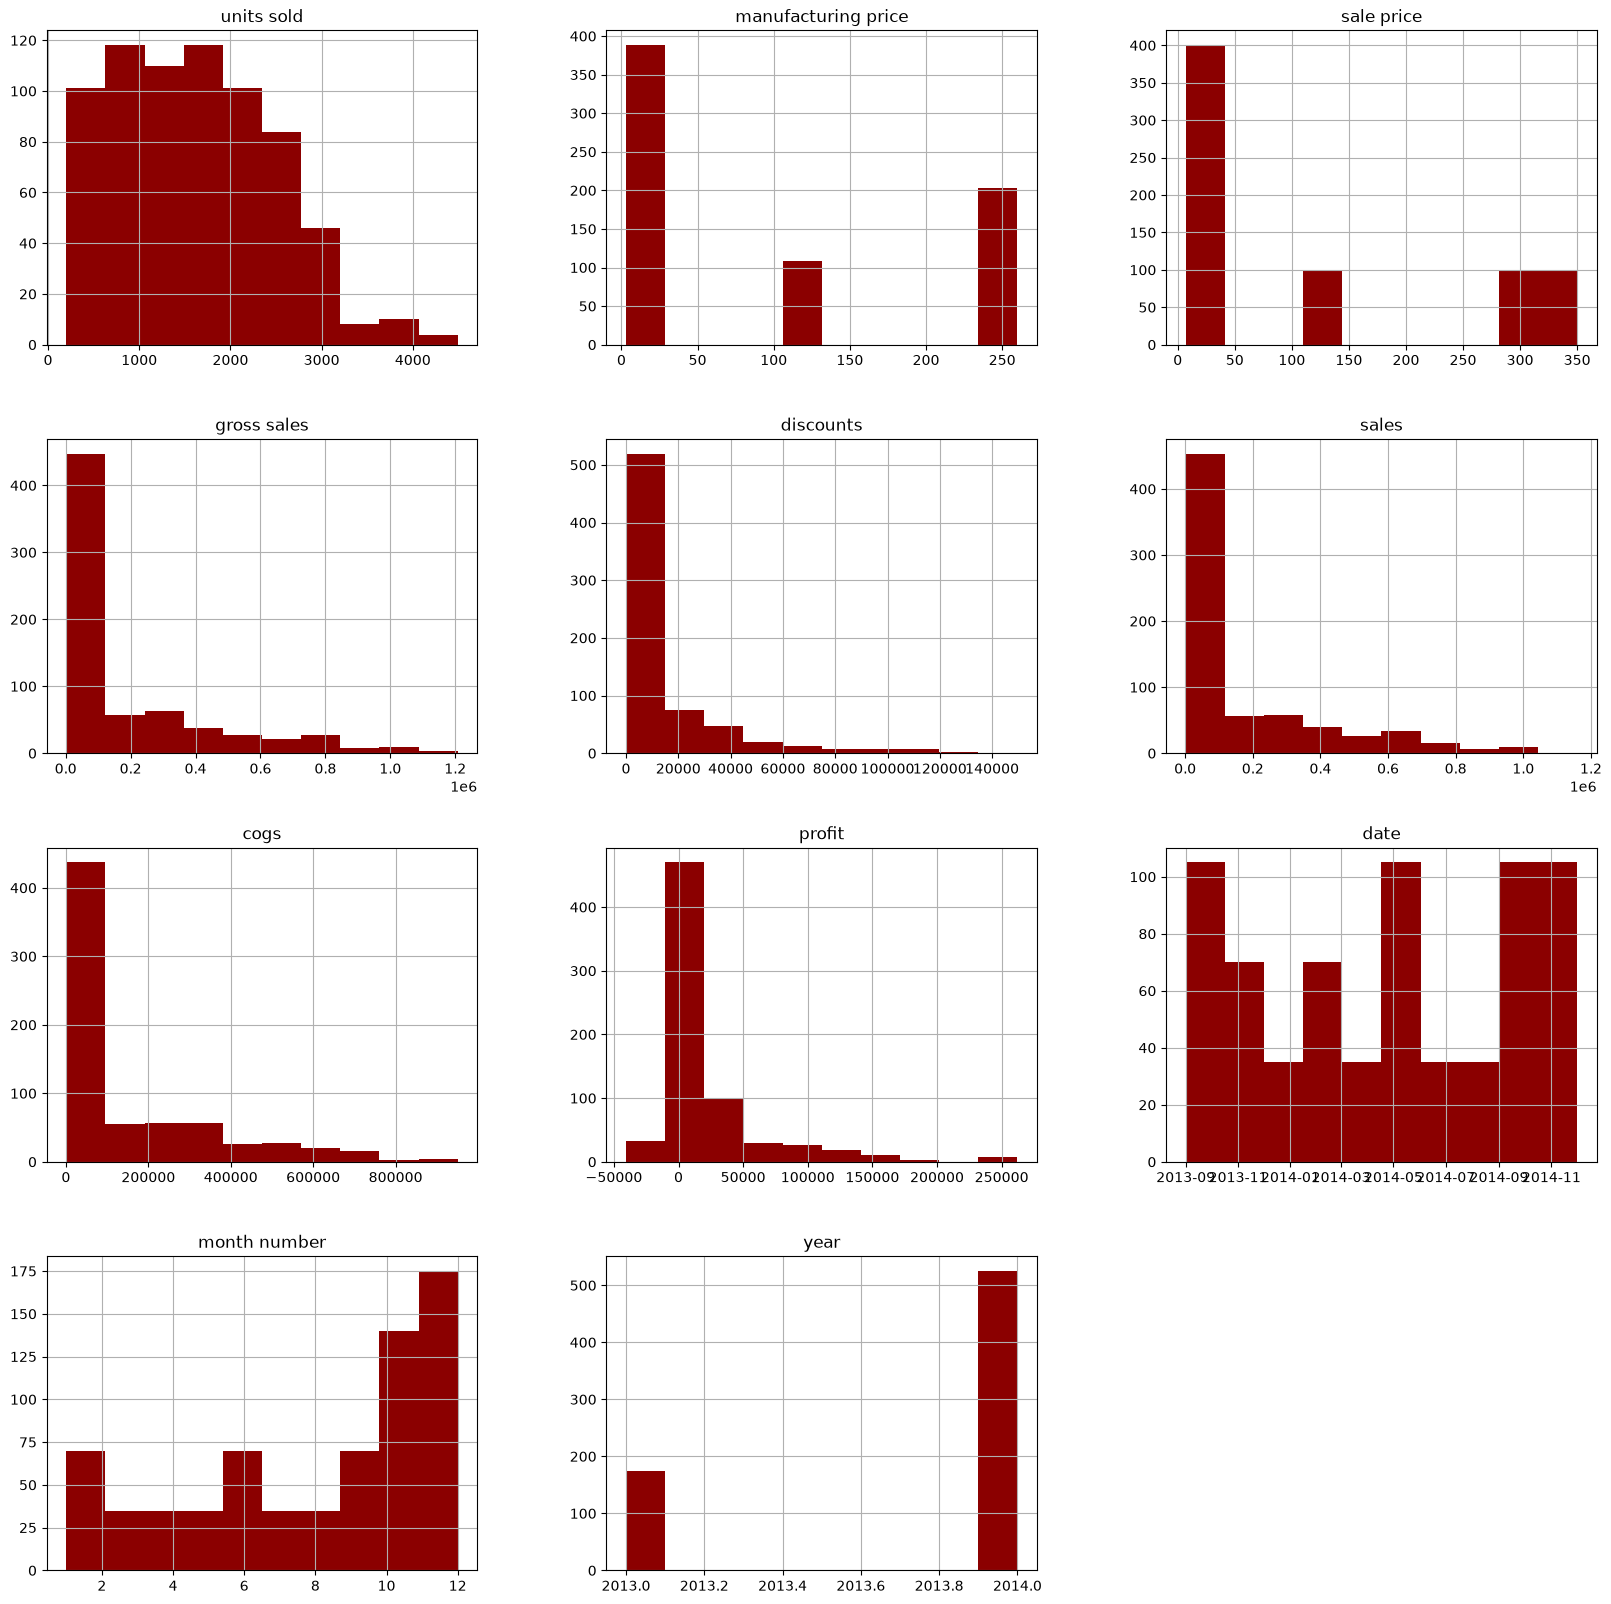

In [13]:
num_bins = 10
histograma = dataset.hist(bins=num_bins, figsize=(20,20), color='darkred')
plt.show()

In [14]:
# Força o Pandas a mostrar números flutuantes com 2 casas decimais sem notação científica
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# visão geral da distribuição estatística dos dados
dataset.describe()

,units sold,manufacturing price,sale price,gross sales,discounts,sales,cogs,profit,date,month number,year
count,700.00,700.00,700.00,700.00,700.00,700.00,700.00,700.00,700,700.00,700.00
mean,1608.27,96.48,118.43,182759.43,13150.35,169609.07,145475.21,24133.86,2014-04-28 21:36:00,7.90,2013.75
min,200.00,3.00,7.00,1799.00,0.00,1655.08,918.00,-40617.50,2013-09-01 00:00:00,1.00,2013.00
25%,905.00,5.00,12.00,17391.75,800.32,15928.00,7490.00,2805.96,2013-12-24 06:00:00,5.75,2013.75
50%,1542.50,10.00,20.00,37980.00,2585.25,35540.20,22506.25,9242.20,2014-05-16 12:00:00,9.00,2014.00
75%,2228.75,250.00,300.00,279025.00,15956.35,261077.50,245607.50,22662.00,2014-09-08 12:00:00,10.25,2014.00
max,4492.00,260.00,350.00,1207500.00,149677.50,1159200.00,950625.00,262200.00,2014-12-01 00:00:00,12.00,2014.00
std,867.41,108.60,136.78,254262.28,22962.93,236726.35,203865.51,42760.63,NaN,3.38,0.43


Podemos observar, através da distância entre o segundo e o terceiro quartil, da diferença entre a mediana e a média e do alto desvio padrão (std), que nossos dados possuem assimetria, o que já nos indica uma elevada dispersão e a presença de valores outliers.

## 4.2. Desempenho por Segmento
Qual segmento de negócio gera o maior lucro e qual entrega a melhor margem de lucro percentual?

In [15]:
# Calculando informações relevantes
df_segment = dataset.groupby('segment')[['sales', 'profit', 'units sold']].sum()
df_segment

,sales,profit,units sold
segment,,,
Channel Partners,1800593.64,1316803.14,161261
Enterprise,19611694.38,-614545.62,168549
Government,52504260.68,11388173.18,470665
Midmarket,2381883.09,660103.09,172176
Small Business,42427918.50,4143168.50,153137


In [16]:
#  Calculando a margem bruta dos segmentos
df_segment['gross margin'] = (df_segment['profit'] / df_segment['sales'])*100
df_segment

,sales,profit,units sold,gross margin
segment,,,,
Channel Partners,1800593.64,1316803.14,161261,73.13
Enterprise,19611694.38,-614545.62,168549,-3.13
Government,52504260.68,11388173.18,470665,21.69
Midmarket,2381883.09,660103.09,172176,27.71
Small Business,42427918.50,4143168.50,153137,9.77


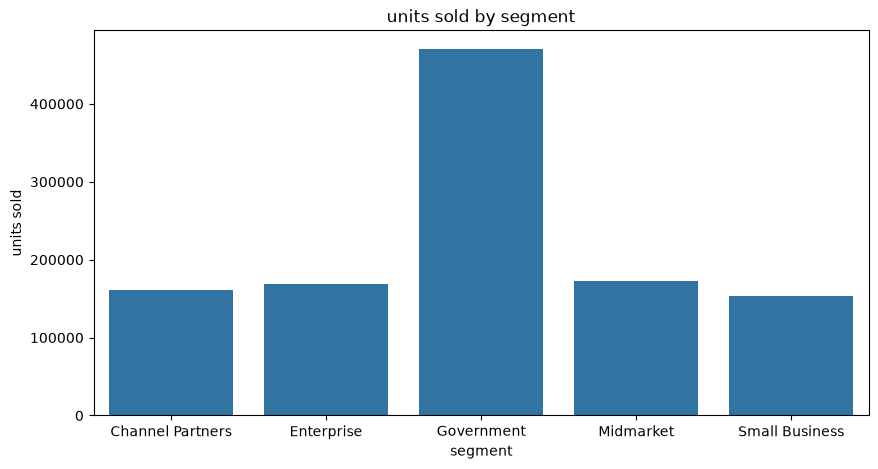

In [17]:
# Grafico de unidades vendidas por segmento  

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_segment,
    x ='segment',
    y ='units sold', 
)

plt.title('units sold by segment')
plt.xlabel('segment')
plt.ylabel('units sold')
plt.show()

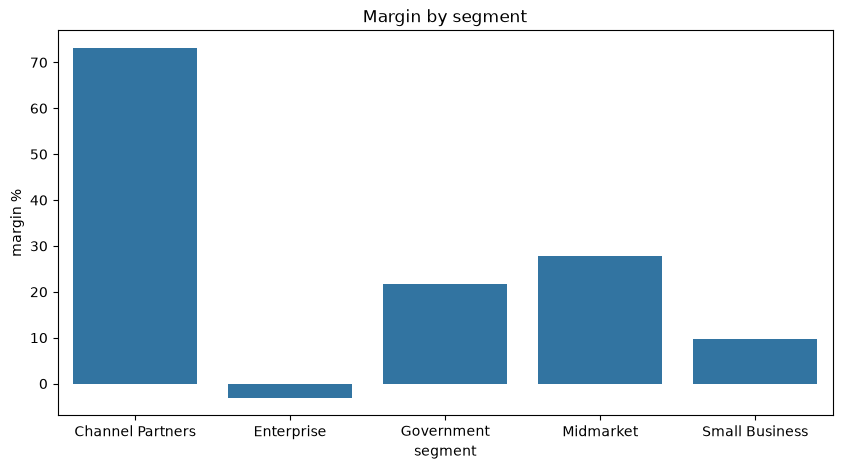

In [18]:
# segment Vs Margin pct 
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_segment,
    x ='segment',
    y ='gross margin', 
)

plt.title('Margin by segment')
plt.xlabel('segment')
plt.ylabel('margin %')
plt.show()

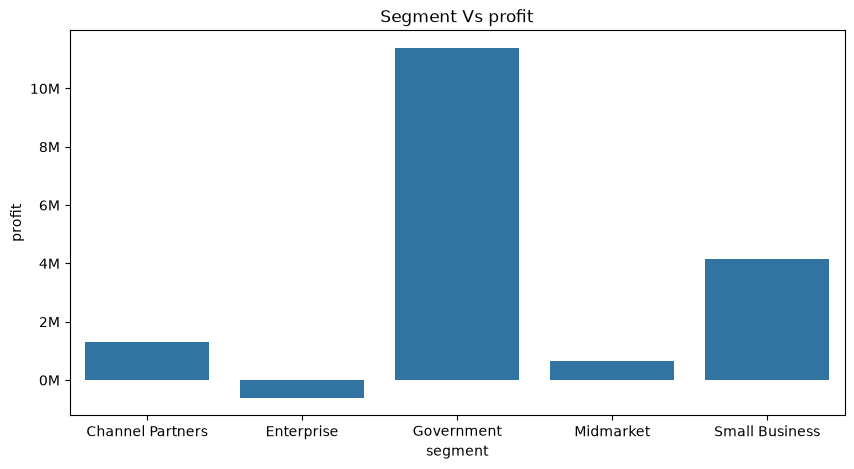

In [19]:
# segment Vs profit

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_segment,
    x ='segment',
    y ='profit', 
)

plt.title('Segment Vs profit')
plt.xlabel('segment')
plt.ylabel('profit')
# Formata o eixo Y para exibir em milhões (ex: 1M, 2M, 3M)
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))
plt.show()

In [20]:
# Calculando Participação (%) de cada categoria no volume total de vendas.
total_unidade_vendidas = df_segment['units sold'].sum()
df_segment['pct total units'] = (df_segment['units sold'] / total_unidade_vendidas) * 100
df_segment[['sales', 'gross margin', 'units sold', 'pct total units']]
df_segment

,sales,profit,units sold,gross margin,pct total units
segment,,,,,
Channel Partners,1800593.64,1316803.14,161261,73.13,14.32
Enterprise,19611694.38,-614545.62,168549,-3.13,14.97
Government,52504260.68,11388173.18,470665,21.69,41.81
Midmarket,2381883.09,660103.09,172176,27.71,15.29
Small Business,42427918.50,4143168.50,153137,9.77,13.60


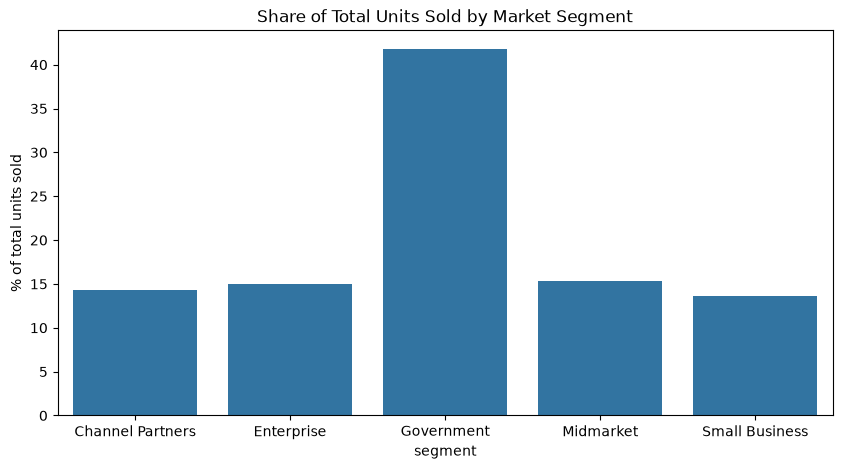

In [21]:
# quanto as vendas de cadas segmento representa em relação as vendas totais
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_segment,
    x ='segment',
    y ='pct total units', 
)

plt.title('Share of Total Units Sold by Market Segment')
plt.xlabel('segment')
plt.ylabel('% of total units sold')
plt.show()

In [22]:
# Participação na Receita por segmento
receita_liquida_total = df_segment['sales'].sum()
df_segment['revenue share by segment'] = (df_segment['sales'] / receita_liquida_total)*100

df_segment

,sales,profit,units sold,gross margin,pct total units,revenue share by segment
segment,,,,,,
Channel Partners,1800593.64,1316803.14,161261,73.13,14.32,1.52
Enterprise,19611694.38,-614545.62,168549,-3.13,14.97,16.52
Government,52504260.68,11388173.18,470665,21.69,41.81,44.22
Midmarket,2381883.09,660103.09,172176,27.71,15.29,2.01
Small Business,42427918.50,4143168.50,153137,9.77,13.60,35.74


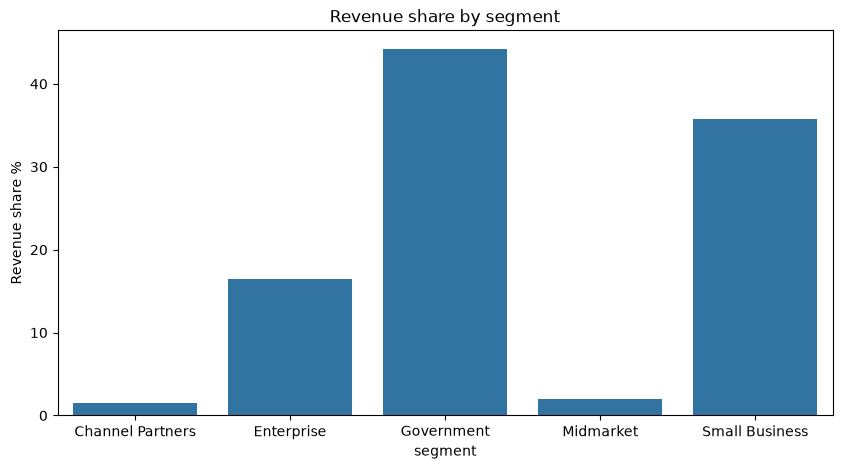

In [23]:
# Visualizando o percentual de participação na receita de cada segmento
plt.figure(figsize=(10,5))

sns.barplot(
    data=df_segment,
    x='segment',
    y='revenue share by segment'
)
plt.title('Revenue share by segment')
plt.xlabel('segment')
plt.ylabel('Revenue share %')
plt.show()

### Conclusão
Os segmentos que mais geraram lucro foram **Government**, com 11 milhões, e **Small Business**, com 4 milhões; juntos representam 80% da receita total gerada. Já entre os segmentos que possuem maior margem, temos **channel partners** com 73%, **Midmarket** com 28% e **Government** com 22%; 

Observações:
* O segmento Channel Partners, apesar de sua grande **margem (73%)**, representa um **lucro de 1,3 milhão**.
* Já o segmento de **Enterprise** está com um **lucro negativo** de 615 mil e uma margem negativa de 3%. O prejuízo vem do alto valor do custo das mercadorias vendidas (COGS).

## 4.3. Análise Geográfica 
Quais países são os mais lucrativos e como se comporta o volume de unidades vendidas entre eles?

In [24]:
# somando os total de lucro e unidades vendidas por país
df_country = dataset.groupby('country')[['units sold', 'gross sales', 'discounts', 'sales', 'profit']].sum()
df_country

,units sold,gross sales,discounts,sales,profit
country,,,,,
Canada,247422,26932163.50,2044508.62,24887654.89,3529228.89
France,240925,26081674.50,1727502.23,24354172.29,3781020.79
Germany,201493,24921467.50,1416126.68,23505340.82,3680388.82
Mexico,203325,22726935.00,1777582.89,20949352.11,2907523.11
United States of America,232623,27269358.00,2239527.85,25029830.18,2995540.68


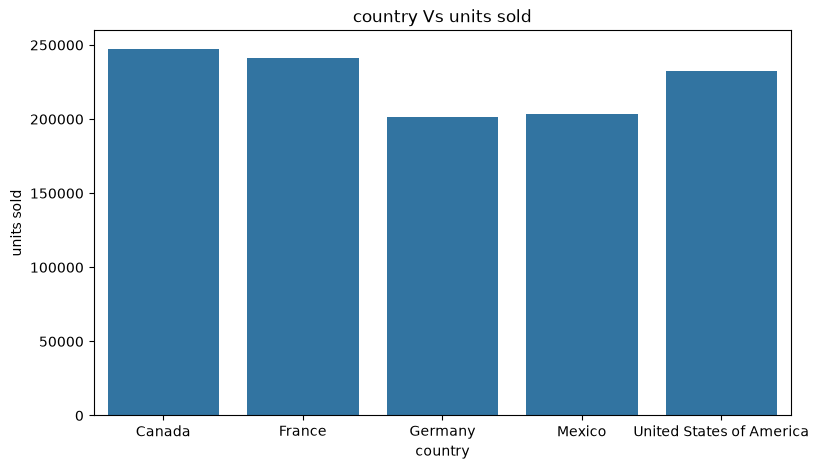

In [25]:
# country Vs units sold
plt.figure(figsize=(9, 5))
sns.barplot(df_country, x='country', y='units sold')
plt.title('country Vs units sold')
plt.show()


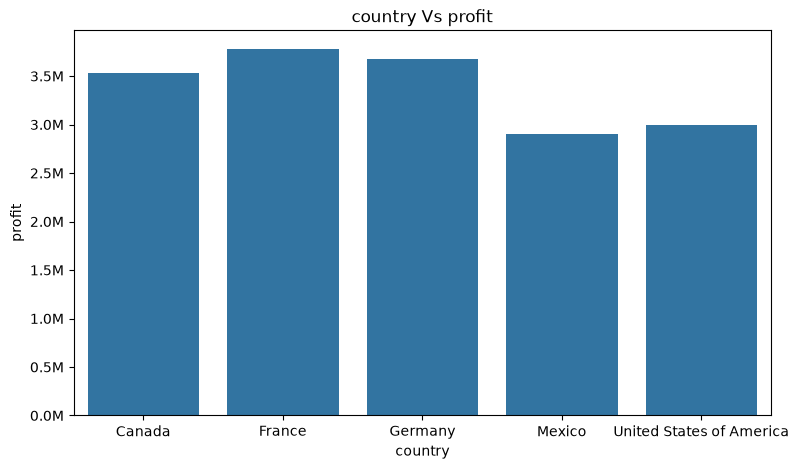

In [26]:
# country Vs profit
plt.figure(figsize=(9, 5))
sns.barplot(df_country, x='country', y='profit')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.title('country Vs profit')

plt.show()

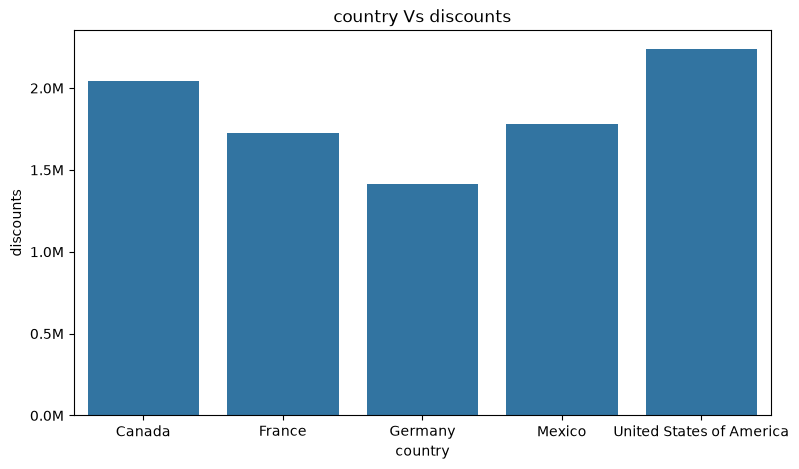

In [27]:
# country Vs discounts
plt.figure(figsize=(9, 5))
sns.barplot(df_country, x='country', y='discounts')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.title('country Vs discounts')
plt.show()

In [28]:
# Calculando a margim bruta (gross margin) de cada país 
df_country['gross margin pct'] = (df_country['profit'] / df_country['sales'])*100
df_country


,units sold,gross sales,discounts,sales,profit,gross margin pct
country,,,,,,
Canada,247422,26932163.50,2044508.62,24887654.89,3529228.89,14.18
France,240925,26081674.50,1727502.23,24354172.29,3781020.79,15.53
Germany,201493,24921467.50,1416126.68,23505340.82,3680388.82,15.66
Mexico,203325,22726935.00,1777582.89,20949352.11,2907523.11,13.88
United States of America,232623,27269358.00,2239527.85,25029830.18,2995540.68,11.97


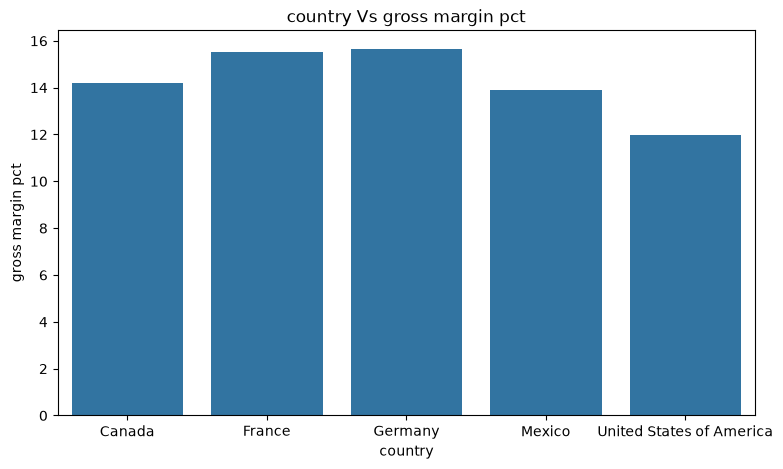

In [29]:
# country Vs gross margin pct
plt.figure(figsize=(9, 5))
sns.barplot(df_country, x='country', y='gross margin pct')
plt.title('country Vs gross margin pct')

plt.show()

In [30]:
# Calculando o Ticket médio de cada país 
df_country['avg ticket value'] = df_country['gross sales']/ df_country['units sold']
df_country

,units sold,gross sales,discounts,sales,profit,gross margin pct,avg ticket value
country,,,,,,,
Canada,247422,26932163.50,2044508.62,24887654.89,3529228.89,14.18,108.85
France,240925,26081674.50,1727502.23,24354172.29,3781020.79,15.53,108.26
Germany,201493,24921467.50,1416126.68,23505340.82,3680388.82,15.66,123.68
Mexico,203325,22726935.00,1777582.89,20949352.11,2907523.11,13.88,111.78
United States of America,232623,27269358.00,2239527.85,25029830.18,2995540.68,11.97,117.23


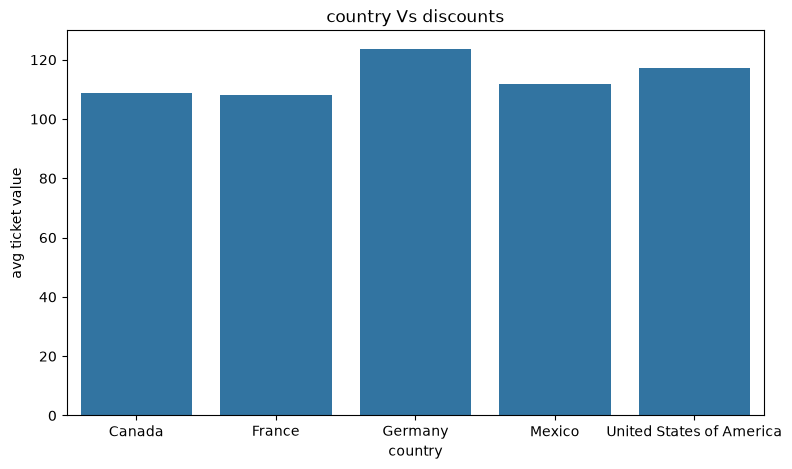

In [31]:
# País vs Ticket médio
plt.figure(figsize=(9, 5))
sns.barplot(df_country, x='country', y='avg ticket value')
plt.title('country Vs discounts')

plt.show()

In [32]:
df_country

,units sold,gross sales,discounts,sales,profit,gross margin pct,avg ticket value
country,,,,,,,
Canada,247422,26932163.50,2044508.62,24887654.89,3529228.89,14.18,108.85
France,240925,26081674.50,1727502.23,24354172.29,3781020.79,15.53,108.26
Germany,201493,24921467.50,1416126.68,23505340.82,3680388.82,15.66,123.68
Mexico,203325,22726935.00,1777582.89,20949352.11,2907523.11,13.88,111.78
United States of America,232623,27269358.00,2239527.85,25029830.18,2995540.68,11.97,117.23


### Conclusão
Os países que mais geraram lucro são França (3,8 milhões), seguido por Alemanha (3,7 milhões) e Canadá (3,5 milhões). Em relação ao número de unidades vendidas, Canadá e França são os que estão no top 1 e 2, respectivamente; Canadá com 247 mil unidades vendidas e França com 241 mil. Já a Alemanha se destaca como o país com menos unidades vendidas (201 mil), mas ainda assim é o segundo país com maior lucro.

## 4.4. Impacto dos Descontos
A concessão de descontos (Discount Band) está alavancando o lucro total ou reduzindo a margem bruta da empresa?

In [33]:
# Calculando valores relevantes para cada grupo de desconto

df_agrupado = dataset.groupby(["discount band"]).agg(
        lucro_total=("profit", "sum"),
        receita_liquida=("sales", "sum"),
        receita_bruta=("gross sales", "sum"),
        descontos_totais=("discounts", "sum"),
        unidades_vendidas=("units sold", "sum")
    ).reset_index()


df_agrupado["margem_bruta_pct"] = (
    df_agrupado['lucro_total'] 
    / df_agrupado['receita_liquida']  
) * 100


df_agrupado["taxa_desconto_pct"] = (
    df_agrupado["descontos_totais"]
    / df_agrupado["receita_bruta"] * 100
)

df_agrupado.sort_values(
    "lucro_total", ascending=False
)

,discount band,lucro_total,receita_liquida,receita_bruta,descontos_totais,unidades_vendidas,margem_bruta_pct,taxa_desconto_pct
1,Low,6188857.71,34629778.71,35515454.50,885675.81,261854,17.87,2.49
2,Medium,5579522.84,38780430.84,41782977.00,3002546.17,379693,14.39,7.19
0,High,3388866.74,37372486.74,42689513.00,5317026.29,398079,9.07,12.46
3,None,1736455.00,7943654.00,7943654.00,0.00,86162,21.86,0.00


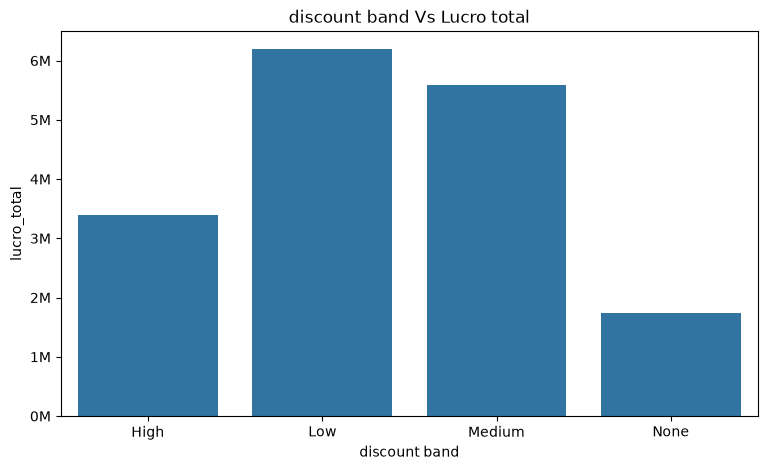

In [34]:
plt.figure(figsize=(9, 5))
sns.barplot(df_agrupado, x='discount band', y='lucro_total')
plt.title('discount band Vs Lucro total')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))
plt.show()

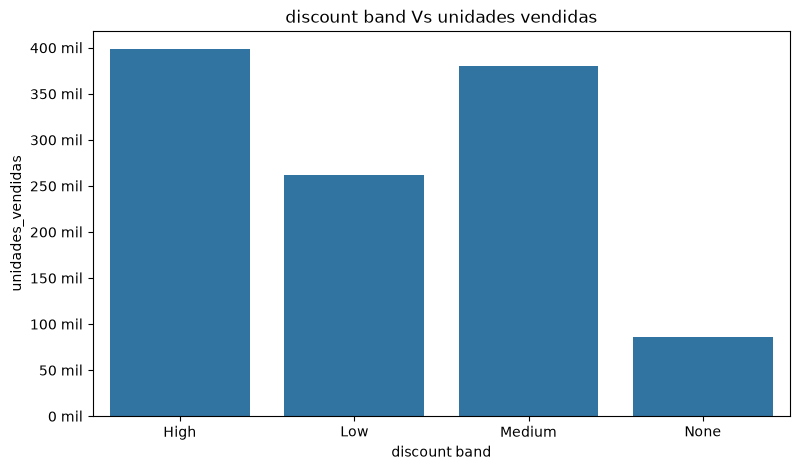

In [35]:
plt.figure(figsize=(9, 5))
sns.barplot(df_agrupado, x='discount band', y='unidades_vendidas')
plt.title('discount band Vs unidades vendidas')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f} mil'))
plt.show()

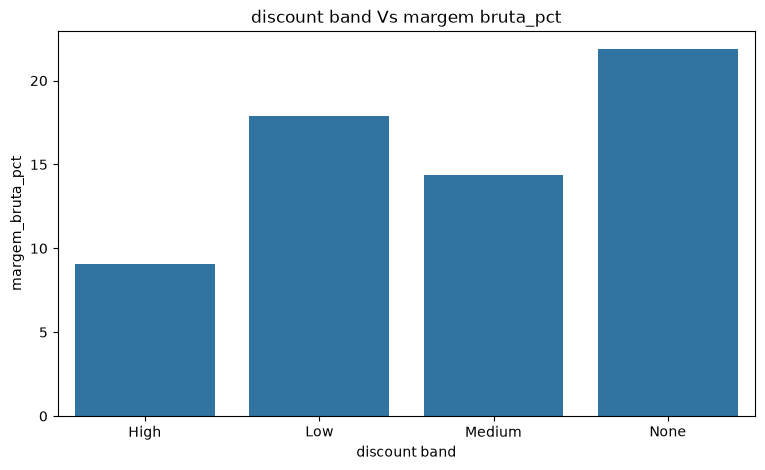

In [36]:
plt.figure(figsize=(9, 5))
sns.barplot(df_agrupado, x='discount band', y='margem_bruta_pct')
plt.title('discount band Vs margem bruta_pct')
plt.show()

### Conclusão

Embora a faixa de desconto Medium tenha registrado um volume de vendas 45% superior ao da faixa Low, ela gerou apenas cerca de 90% do lucro obtido por esta última. Assim, o **maior volume de vendas não foi suficiente** para superar a lucratividade total da faixa Low. A margem de lucro apresentou uma queda de aproximadamente 19% entre as faixas Low e Medium.

## 4.5 Sazonalidade e Tendência
Como as vendas líquidas e o lucro evoluíram ao longo dos meses e anos registrados na base?

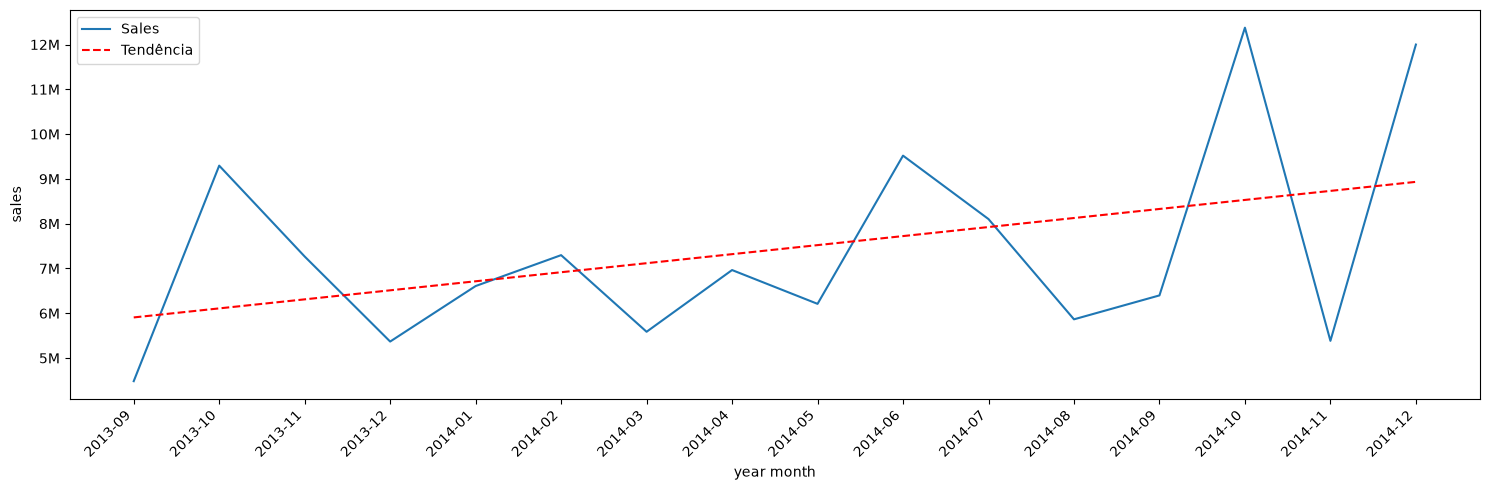

In [37]:
# Grafico das vendas liquidas no período e tendencia

# Agrupa mantendo a ordem cronológica
dataset['year month'] = dataset['date'].dt.to_period('M')
df_sales = dataset.groupby('year month')['sales'].sum().reset_index()

# Converte para string para o Seaborn tratar como categoria ordenada
df_sales['year month'] = df_sales['year month'].astype(str)

# Plota o gráfico principal
plt.figure(figsize=(15, 5))
ax = sns.lineplot(data=df_sales, x='year month', y='sales', label='Sales')

# Calcula e plota a tendência usando os índices numéricos
x_numbers = np.arange(len(df_sales))
y_values = df_sales['sales'].values

ab = np.polyfit(x_numbers, y_values, 1)
l = np.polyval(ab, x_numbers)

ax.plot(
    x_numbers, l, color='red', linestyle='--', label='Tendência'
)

# Formatação de eixos
plt.gca().yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M')
)
plt.xticks(rotation=45, ha='right')  # Evita sobreposição de datas
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
# Calculando o crescimento médio do receita liquido no periodo (crescimento composta)

# Valor inicial e final da coluna 'profit'
valor_inicial = df_sales['sales'].iloc[0]
valor_final = df_sales['sales'].iloc[-1]

# Número de períodos (ex: quantidade de meses - 1)
n = len(df_sales) - 1

# Cálculo da CAGR
cagr = ((valor_final / valor_inicial) ** (1 / n) - 1) * 100

print(f'Taxa Média Composta: {cagr:.2f}% por período')

Taxa Média Composta: 6.78% por período


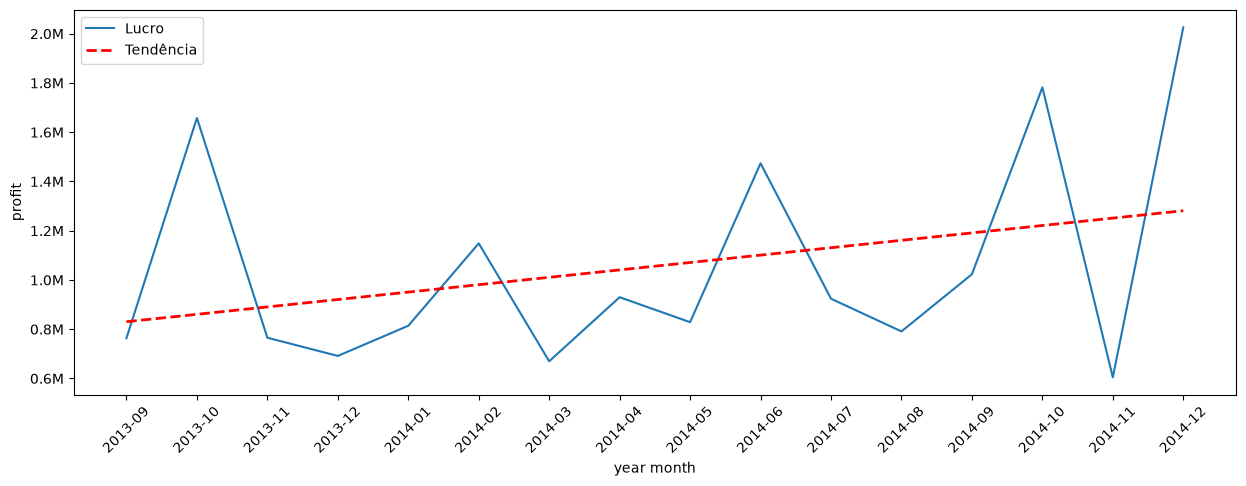

In [39]:
# Grafico do lucro ao longo do período



# lucro (profit) ao longo dos meses
dataset['year month'] = dataset['date'].dt.to_period('M')
df_profit = dataset.groupby('year month')['profit'].sum().reset_index()
df_profit['year month'] = df_profit['year month'].astype(str)

plt.figure(figsize=(15, 5))
ax = sns.lineplot(data=df_profit, x='year month', y='profit', label='Lucro')
x_nums = np.arange(len(df_profit))
y_vals = df_profit['profit'].values

# Calcular a linha de tendência (grau 1 = linha reta)
z = np.polyfit(x_nums, y_vals, 1)
p = np.polyval(z, x_nums)

# Plotar a linha de tendência por cima do gráfico do Seaborn
ax.plot(
    df_profit['year month'],
    p,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Tendência',
)

# Formata o eixo Y 
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x*1e-6:.1f}M')
)
plt.legend()
plt.xticks(rotation=45)  # Opcional: rotaciona os meses se estiverem sobrepostos
plt.show()

In [40]:
# Calculando o crescimento médio do lucro no periodo (crescimento composta)

# Valor inicial e final da coluna 'profit'
valor_inicial = df_profit['profit'].iloc[0]
valor_final = df_profit['profit'].iloc[-1]

# Número de períodos (ex: quantidade de meses - 1)
n = len(df_profit) - 1

# Cálculo da CAGR
cagr = ((valor_final / valor_inicial) ** (1 / n) - 1) * 100

print(f'Taxa Média Composta: {cagr:.2f}% por período')

Taxa Média Composta: 6.72% por período


### Conclusão
* **Vendas Líquidas (Sales):** Apresentaram uma taxa de crescimento composto de 6,78% ao longo dos 15 meses do período analisado.
* **Lucro (Profit):** Registraram uma taxa de crescimento composto de 6,72% no mesmo período.

## Exportação dos dados

In [41]:
# Exportar dataset tratado para CSV

dataset = dataset[['segment', 'country', 'product', 'discount band', 'units sold',
       'manufacturing price', 'sale price', 'gross sales', 'discounts',
       'sales', 'cogs', 'profit', 'date']]


dataset.to_csv('../data/Financials.csv', index=False)
print('>>> dado exportado com sucesso!')

>>> dado exportado com sucesso!
